# Customer churn: EDA and model review

UCI Online Retail II: a UK online gift wholesaler, Dec 2009 – Dec 2011. This notebook explains the choices in `train.py`:
1. What the raw data looks like and what gets cleaned
2. How churn is defined without leaking the future
3. Why churn is seasonal, and what that does to a model
4. What drives churn, and where the model beats a simple rule
5. What the RFM segments mean

In [1]:
import sys
sys.path.insert(0, "..")
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from train import FEATURES, HORIZON, NON_PRODUCT, RFM, load, models, snapshot, split

pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.3f}".format)

## 1. Cleaning

In [2]:
raw = pd.read_csv("../data/online_retail_ii.csv", parse_dates=["InvoiceDate"], dtype={"Invoice": str, "StockCode": str})
d, steps = raw, {"raw rows (both sheets)": len(raw)}
d = d.drop_duplicates();                steps["exact duplicates removed"] = len(d)
d = d[d["Customer ID"].notna()];        steps["has a customer ID"] = len(d)
d = d[~d.StockCode.isin(NON_PRODUCT)];  steps["product lines only (no postage, fees, adjustments)"] = len(d)
d = d[d.Price > 0];                     steps["price > 0"] = len(d)
pd.Series(steps).to_frame("rows")

,rows
raw rows (both sheets),1067371
exact duplicates removed,1033036
has a customer ID,797885
"product lines only (no postage, fees, adjustments)",794244
price > 0,794183


- **Duplicates:** 1–9 Dec 2010 appears in both Excel sheets, and some lines were scanned twice.
- **No customer ID:** about a quarter of the remaining rows are guest checkouts. They can't be tracked over time, so they can't be used for churn.
- **Non-products:** postage, manual adjustments, bank and Amazon fees, bad-debt write-offs and test items. None of them are something a customer chose to buy.

In [3]:
tx = load()
gross = tx.loc[~tx.is_return, "value"].sum()
print(f"{tx.customer.nunique():,} customers, {tx.invoice.nunique():,} invoices, {tx.date.min().date()} to {tx.date.max().date()}")
print(f"returns/cancellations: {tx.is_return.mean():.1%} of lines, {-tx.loc[tx.is_return, 'value'].sum() / gross:.1%} of gross value")
big = tx[tx.is_return].nsmallest(3, "value")[["customer", "date", "value"]]
big

5,875 customers, 43,877 invoices, 2009-12-01 to 2011-12-09
returns/cancellations: 2.2% of lines, 4.2% of gross value


,customer,date,value
1065883,16446,2011-12-09 09:27:00,"-168,469.600"
587085,12346,2011-01-18 10:17:00,"-77,183.600"
685606,15749,2011-04-18 13:08:00,"-6,539.400"


Some huge orders were cancelled straight away: the largest returns are the same customer's order reversed on the same day. That's why `spend_180` is measured **net** of returns. Without it, one cancelled £168k order put customer 16446 at the top of the call list.

## 2. Defining churn without leakage

Each **snapshot** picks a cutoff date and looks at customers who bought in the 180 days before it:
- **features:** computed only from those 180 days before the cutoff
- **label:** `churned = 1` if the customer makes no purchase in the 90 days after the cutoff

```
 ◄──────── 180-day feature window ────────►│◄──── 90-day label window ────►
                                         cutoff
```

`test_churn.py` checks this rule: adding transactions after the cutoff must not change any feature.

Cutoffs are 90 days apart. The last one whose label window is complete (2011-09-10) is the **out-of-time test**. Every earlier one is training data.

In [4]:
train, test = split(tx)
snaps = pd.concat([train, test])
by_cutoff = snaps.groupby(snaps.cutoff.dt.date).agg(customers=("churned", "size"), churn_rate=("churned", "mean"))
by_cutoff["label window"] = [f"{c:%b %Y} – {(pd.Timestamp(c) + HORIZON):%b %Y}" for c in by_cutoff.index]
by_cutoff["set"] = ["train"] * (len(by_cutoff) - 1) + ["test"]
by_cutoff

,customers,churn_rate,label window,set
cutoff,,,,
2010-06-17,2631,0.506,Jun 2010 – Sep 2010,train
2010-09-15,2813,0.386,Sep 2010 – Dec 2010,train
2010-12-14,3461,0.651,Dec 2010 – Mar 2011,train
2011-03-14,3334,0.572,Mar 2011 – Jun 2011,train
2011-06-12,2630,0.503,Jun 2011 – Sep 2011,train
2011-09-10,2783,0.382,Sep 2011 – Dec 2011,test


## 3. Churn is seasonal

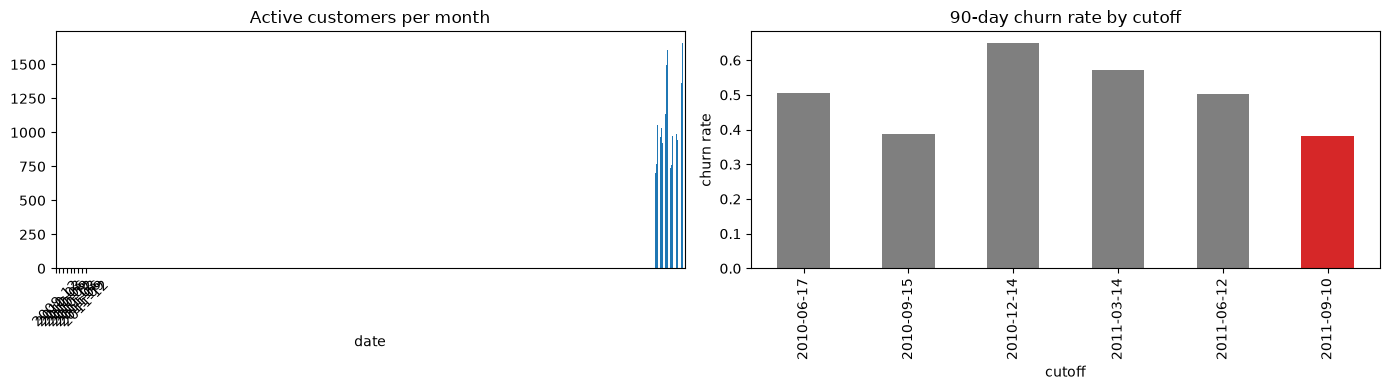

In [5]:
monthly = tx[~tx.is_return].groupby(tx.date.dt.to_period("M")).agg(customers=("customer", "nunique"), revenue=("value", "sum"))
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
monthly.customers.plot.bar(ax=ax[0], title="Active customers per month", color="tab:blue")
ax[0].set_xticks(range(0, len(monthly), 3), monthly.index[::3].astype(str), rotation=45)
by_cutoff.churn_rate.plot.bar(ax=ax[1], title="90-day churn rate by cutoff", color=["tab:gray"] * (len(by_cutoff) - 1) + ["tab:red"])
ax[1].set_ylabel("churn rate")
fig.tight_layout()

Customers order ahead of Christmas, so a label window covering September to December has far less churn: 39% in 2010 and 38% in 2011, against 50–65% in the other quarters.

Training only on higher-churn quarters would misrepresent the test season. The training snapshots include September 2010 so the model has a comparable seasonal window.

Two choices address this:
- **A 6-month feature window.** It's short enough for the Sep 2010 snapshot to have full history.
- **A `peak_season` flag.** It's known at prediction time, and it lets the model shift its churn level by season.

## 4. What drives churn

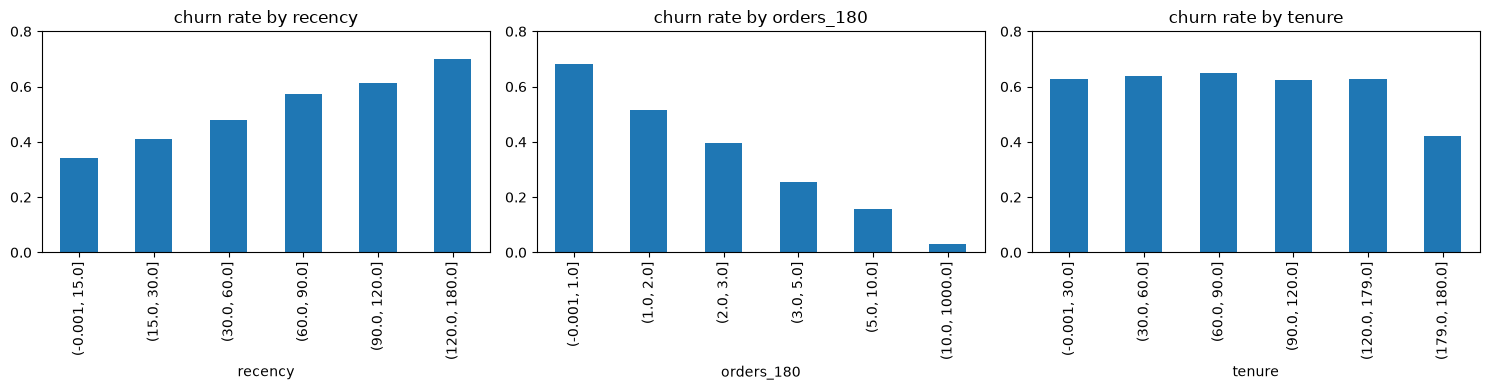

In [6]:
lab = snaps.copy()
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, (col, bins) in zip(ax, [("recency", [0, 15, 30, 60, 90, 120, 180]),
                                ("orders_180", [0, 1, 2, 3, 5, 10, 1000]),
                                ("tenure", [0, 30, 60, 90, 120, 179, 180])]):
    lab.groupby(pd.cut(lab[col], bins, include_lowest=True), observed=True).churned.mean().plot.bar(ax=a, title=f"churn rate by {col}")
    a.set_ylim(0, 0.8)
fig.tight_layout()

- **Recency** has a clear association with churn: the longer since the last order, the higher the churn.
- **Frequency:** one-order customers churn far more than repeat buyers.
- **New customers:** those first seen less than 6 months before the cutoff churn at about 63%, against 42% for established ones. A recency-only rule can't see this, which is a big part of why the model beats it.

## 5. Model results

Cross-validation uses the train snapshots, with folds split by customer because the same customer appears in several snapshots. The test is the later, out-of-time quarter.

In [7]:
cv = pd.read_csv("../results/cv_results.csv", index_col=0)
res = pd.read_csv("../results/test_results.csv", index_col=0)
display(cv)
res

,threshold,roc_auc,f1,precision,recall,accuracy,precision_top20%
model,,,,,,,
logreg,0.367,0.752,0.747,0.638,0.900,0.676,0.787
random_forest,0.406,0.757,0.752,0.655,0.882,0.691,0.797
xgboost,0.372,0.761,0.752,0.651,0.890,0.689,0.801


,roc_auc,f1,precision,recall,accuracy,precision_top20%
model,,,,,,
baseline: always churn,0.500,0.553,0.382,1.000,0.382,0.371
baseline: no order in 90 days,0.656,0.488,0.539,0.445,0.642,0.586
logreg,0.730,0.623,0.530,0.757,0.650,0.601
random_forest,0.737,0.619,0.537,0.732,0.656,0.644
xgboost,0.740,0.605,0.564,0.652,0.674,0.647


### Where the model adds value

The rule "no order in 90 days = churn" can't flag anyone who ordered recently. But a large share of recent buyers still churn.

In [8]:
chosen = cv.roc_auc.idxmax()
model = models()[chosen].fit(train[FEATURES], train.churned)  # train only, so the test stays unseen
test = test.assign(p=model.predict_proba(test[FEATURES])[:, 1])
flag = test.p >= cv.loc[chosen, "threshold"]
recent = test.recency < 90
summary = pd.DataFrame({
    "customers": [recent.sum(), (~recent).sum()],
    "churners": [test.churned[recent].sum(), test.churned[~recent].sum()],
    "rule catches": [0, test.churned[~recent].sum()],
    "model flags": [flag[recent].sum(), flag[~recent].sum()],
    "model catches": [(flag & recent & (test.churned == 1)).sum(), (flag & ~recent & (test.churned == 1)).sum()],
}, index=["ordered in last 90 days", "no order in 90 days"])
summary["model precision"] = summary["model catches"] / summary["model flags"]
summary

,customers,churners,rule catches,model flags,model catches,model precision
ordered in last 90 days,1903,590,0,607,307,0.506
no order in 90 days,880,474,474,624,387,0.620


In [9]:
print(pd.read_csv("../results/feature_importance.csv", index_col=0).sort_values("roc_auc_drop", ascending=False).round(4).to_string())

                 roc_auc_drop
avg_gap                 0.024
tenure                  0.021
recency                 0.014
products_180            0.013
spend_180               0.013
orders_180              0.012
return_rate             0.003
orders_90               0.002
avg_order_value         0.001
uk                      0.000
peak_season             0.000


`peak_season` shows zero importance here. That's expected: every test customer has the same value, so shuffling it can't change their ranking. Its job is calibration across seasons, not ranking within one.

## 6. RFM segments

K-means on log-scaled, standardized recency, frequency (orders) and monetary (net spend), fitted on the test snapshot so each segment's actual churn is known.

In [10]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
saved = joblib.load("../models/churn.joblib")
seg = saved["segmenter"]
Z = seg[:-1].transform(test[RFM])
print("silhouette:", {k: round(silhouette_score(Z, KMeans(k, n_init=10, random_state=0).fit_predict(Z)), 3) for k in range(2, 9)})
test["segment"] = pd.Series(seg.predict(test[RFM]), test.index).map(saved["segment_names"])
profile = pd.read_csv("../results/segments.csv", index_col=0)
g = test.groupby("segment")
profile["new_customers"] = g.tenure.apply(lambda x: (x < 180).mean())  # first seen < 6 months ago
profile["one_order"] = g.orders_180.apply(lambda x: (x == 1).mean())
profile

silhouette: {2: 0.437, 3: 0.356, 4: 0.376, 5: 0.292, 6: 0.31, 7: 0.288, 8: 0.287}


,customers,median_recency,median_orders,median_spend,actual_churn,predicted_churn,spend_share,new_customers,one_order
segment,,,,,,,,,
Champions,301,8.000,8.000,"2,778.040",0.050,0.082,0.526,0.093,0.000
Regulars,887,44.000,3.000,944.490,0.259,0.248,0.315,0.184,0.067
"Recent, low spend",337,7.000,2.000,453.790,0.386,0.377,0.057,0.356,0.356
Lapsing,1258,103.000,1.000,245.380,0.548,0.480,0.102,0.285,0.853


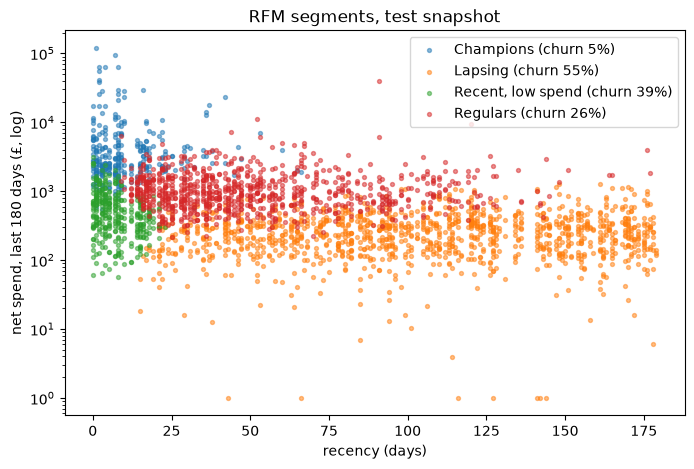

In [11]:
fig, ax = plt.subplots(figsize=(8, 5))
for name, g in test.groupby("segment"):
    ax.scatter(g.recency, g.spend_180 + 1, s=8, alpha=0.5, label=f"{name} (churn {g.churned.mean():.0%})")
ax.set(yscale="log", xlabel="recency (days)", ylabel="net spend, last 180 days (£, log)", title="RFM segments, test snapshot")
ax.legend();

- **k=4 instead of k=2:** silhouette is highest at k=2, but that only splits active customers from lapsed ones. Among k ≥ 3, k=4 scores best, and each of its segments maps to a different action.
- **Champions:** about 11% of customers bring in about half of net spend, and only 5% of them churn.
- **Recent, low spend:** these customers bought within the last week, yet 39% churn. They buy small and rarely: a third are new, and a third have only one order. A recency rule calls them safe, so a welcome or second-order offer is the lever here.
- **Lapsing:** 45% of customers, but only 10% of spend. A cheap, automated win-back email fits them.
- **Regulars:** the biggest pool of spend at risk in `score.py`. This is the call list.

## 7. Retention capacity and missed customers

The F1 threshold does not tell a team with a fixed call budget who fits into that budget. Here the held-out customers are ranked by churn probability and compared with a recency ranking at the same contact capacity. These are retrospective identification rates, not estimates of customers saved by calling.

The threshold confusion matrix uses the training-CV threshold unchanged. No threshold or contact budget is selected from these test results.

In [12]:
from sklearn.metrics import confusion_matrix, roc_auc_score

assert round(roc_auc_score(test.churned, test.p), 3) == res.loc[chosen, 'roc_auc']
ranked = test.sort_values('p', ascending=False, kind='stable')
by_recency = test.sort_values('recency', ascending=False, kind='stable')
rows = []
for fraction in [0.05, 0.10, 0.20, 0.30, 0.50, 1.00]:
    contacts = int(len(test) * fraction)
    selected = ranked.iloc[:contacts]
    found = int(selected.churned.sum())
    rows.append({
        'capacity_pct': fraction * 100,
        'contacts': contacts,
        'churners_found': found,
        'precision': selected.churned.mean(),
        'recall': found / test.churned.sum(),
        'lift_vs_random': selected.churned.mean() / test.churned.mean(),
        'recency_precision': by_recency.iloc[:contacts].churned.mean(),
    })
capacity = pd.DataFrame(rows).set_index('capacity_pct')
assert capacity.churners_found.is_monotonic_increasing
assert capacity.loc[100, 'churners_found'] == test.churned.sum()
assert round(capacity.loc[20, 'precision'], 3) == res.loc[chosen, 'precision_top20%']
capacity.to_csv('../results/retention_capacity.csv')
display(capacity.round(3))

cm = pd.DataFrame(
    confusion_matrix(test.churned, flag.astype(int), labels=[0, 1]),
    index=['Actually stayed', 'Actually churned'],
    columns=['Predicted stay', 'Predicted churn'],
)
assert cm.to_numpy().sum() == len(test)
cm.to_csv('../results/threshold_confusion.csv')
print(f'Training-CV threshold: {cv.loc[chosen, "threshold"]:.3f}')
display(cm)

,contacts,churners_found,precision,recall,lift_vs_random,recency_precision
capacity_pct,,,,,,
5.000,139,103,0.741,0.097,1.938,0.626
10.000,278,197,0.709,0.185,1.854,0.601
20.000,556,360,0.647,0.338,1.694,0.586
30.000,834,505,0.606,0.475,1.584,0.549
50.000,1391,769,0.553,0.723,1.446,0.495
100.000,2783,1064,0.382,1.000,1.000,0.382


Training-CV threshold: 0.372


,Predicted stay,Predicted churn
Actually stayed,1182,537
Actually churned,370,694


## 8. Are the probabilities reliable?

A good ranking does not guarantee that a score of 0.6 means a 60% chance of churn. The reliability table groups test customers by predicted probability and compares the average prediction with the observed churn rate. Counts matter: a sparse bin is a weak basis for a decision.

Brier score measures squared probability error; lower is better. The constant reference uses training prevalence, not a prevalence fitted to this test quarter. This is a diagnostic only: no calibration model is fitted on the holdout.

Brier score: model 0.199; constant training prevalence 0.258


,customers,mean_probability,observed_churn
probability_bin,,,
"(-0.001, 0.1]",185,0.043,0.027
"(0.1, 0.2]",483,0.154,0.141
"(0.2, 0.3]",460,0.250,0.278
"(0.3, 0.4]",617,0.356,0.434
"(0.4, 0.5]",460,0.447,0.480
"(0.5, 0.6]",306,0.546,0.588
"(0.6, 0.7]",180,0.646,0.678
"(0.7, 0.8]",84,0.737,0.762
"(0.8, 0.9]",8,0.813,1.000


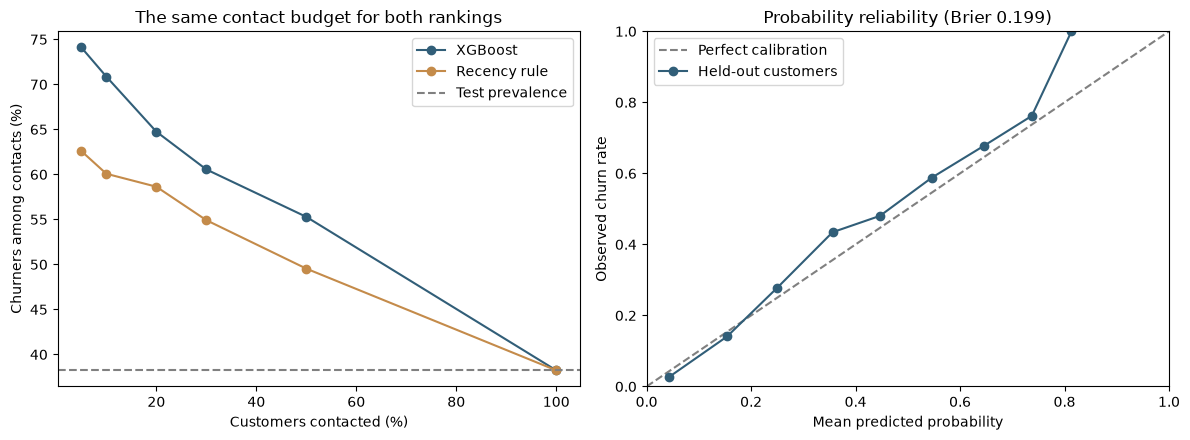

In [13]:
from sklearn.metrics import brier_score_loss

reliability = test.assign(
    probability_bin=pd.cut(test.p, bins=np.linspace(0, 1, 11), include_lowest=True)
).groupby('probability_bin', observed=True).agg(
    customers=('churned', 'size'),
    mean_probability=('p', 'mean'),
    observed_churn=('churned', 'mean'),
)
assert reliability.customers.sum() == len(test)
assert reliability[['mean_probability', 'observed_churn']].apply(lambda x: x.between(0, 1).all()).all()
reliability.to_csv('../results/calibration.csv')
brier = brier_score_loss(test.churned, test.p)
reference_brier = brier_score_loss(test.churned, np.full(len(test), train.churned.mean()))
print(f'Brier score: model {brier:.3f}; constant training prevalence {reference_brier:.3f}')
display(reliability.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
capacity[['precision', 'recency_precision']].rename(
    columns={'precision': 'XGBoost', 'recency_precision': 'Recency rule'}
).mul(100).plot(ax=axes[0], marker='o', color=['#315e78', '#c48b4a'])
axes[0].axhline(test.churned.mean() * 100, color='gray', linestyle='--', label='Test prevalence')
axes[0].set(xlabel='Customers contacted (%)', ylabel='Churners among contacts (%)',
            title='The same contact budget for both rankings')
axes[0].legend()
axes[1].plot([0, 1], [0, 1], '--', color='gray', label='Perfect calibration')
axes[1].plot(reliability.mean_probability, reliability.observed_churn, 'o-',
             color='#315e78', label='Held-out customers')
axes[1].set(xlim=(0, 1), ylim=(0, 1), xlabel='Mean predicted probability',
            ylabel='Observed churn rate', title=f'Probability reliability (Brier {brier:.3f})')
axes[1].legend()
fig.tight_layout()
fig.savefig('../results/retention_diagnostics.png', dpi=120)

The capacity table separates two decisions: how many customers can be contacted, and how well the model identifies inactivity within that budget. It cannot establish campaign uplift. That needs a randomized intervention with an untreated group. Before using the probability values operationally, calibration should also be checked on several later periods rather than adjusted to fit this single quarter.